# Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Loading and Reading .csv file
data=pd.read_csv("ML_Synthetic_payments.csv")
data

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
99995,10,PAYMENT,4020.66,C1410794718,159929.0,155908.34,M1257036576,0.00,0.00,0,0
99996,10,PAYMENT,18345.49,C744303677,6206.0,0.00,M1785344556,0.00,0.00,0,0
99997,10,CASH_IN,183774.91,C104331851,39173.0,222947.91,C36392889,54925.05,0.00,0,0
99998,10,CASH_OUT,82237.17,C707662966,6031.0,0.00,C1553004158,592635.66,799140.46,0,0


In [3]:
data.size

1100000

In [4]:
data.shape

(100000, 11)

In [5]:
data.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [6]:
data=data.drop("step",axis=1)
print("Dropped Successfully")

Dropped Successfully


In [7]:
data.index

RangeIndex(start=0, stop=100000, step=1)

In [8]:
data.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [9]:
data.tail()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
99995,PAYMENT,4020.66,C1410794718,159929.0,155908.34,M1257036576,0.00,0.00,0,0
99996,PAYMENT,18345.49,C744303677,6206.0,0.00,M1785344556,0.00,0.00,0,0
99997,CASH_IN,183774.91,C104331851,39173.0,222947.91,C36392889,54925.05,0.00,0,0
99998,CASH_OUT,82237.17,C707662966,6031.0,0.00,C1553004158,592635.66,799140.46,0,0
99999,PAYMENT,20096.56,C1868032458,110117.0,90020.44,M1419201886,0.00,0.00,0,0


# EDA - Exploratory Data Analysis

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   type            100000 non-null  str    
 1   amount          100000 non-null  float64
 2   nameOrig        100000 non-null  str    
 3   oldbalanceOrg   100000 non-null  float64
 4   newbalanceOrig  100000 non-null  float64
 5   nameDest        100000 non-null  str    
 6   oldbalanceDest  100000 non-null  float64
 7   newbalanceDest  100000 non-null  float64
 8   isFraud         100000 non-null  int64  
 9   isFlaggedFraud  100000 non-null  int64  
dtypes: float64(5), int64(2), str(3)
memory usage: 7.6 MB


In [11]:
data.describe()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,1.000000e+05,1.000000e+05,1.000000e+05,1.000000e+05,1.000000e+05,100000.000000,100000.0
mean,1.736022e+05,8.777575e+05,8.940619e+05,8.805048e+05,1.184041e+06,0.001160,0.0
std,3.443003e+05,2.673284e+06,2.711318e+06,2.402267e+06,2.802350e+06,0.034039,0.0
min,3.200000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
25%,9.963562e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
50%,5.274552e+04,2.006150e+04,0.000000e+00,2.083943e+04,4.990918e+04,0.000000,0.0
75%,2.117631e+05,1.901920e+05,2.148132e+05,5.882724e+05,1.058186e+06,0.000000,0.0
max,1.000000e+07,3.379739e+07,3.400874e+07,3.400874e+07,3.894623e+07,1.000000,0.0


In [12]:
# Remove C/M prefix from account IDs
data['nameOrig'] = data['nameOrig'].str[1:]
data['nameDest'] = data['nameDest'].str[1:]

# Convert to numeric
data['nameOrig'] = pd.to_numeric(data['nameOrig'])
data['nameDest'] = pd.to_numeric(data['nameDest'])

In [13]:
data["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    100000
Name: count, dtype: int64

In [14]:
data=data.drop("isFlaggedFraud",axis=1)
print("Dropped Successfully")

Dropped Successfully


In [15]:
data.isna().sum()

type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64

In [16]:
data.isnull().sum()

type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64

In [17]:
data.duplicated().sum()

np.int64(0)

In [18]:
data["type"].value_counts()

type
PAYMENT     39512
CASH_OUT    30718
CASH_IN     20185
TRANSFER     8597
DEBIT         988
Name: count, dtype: int64

# Distribution Analysis

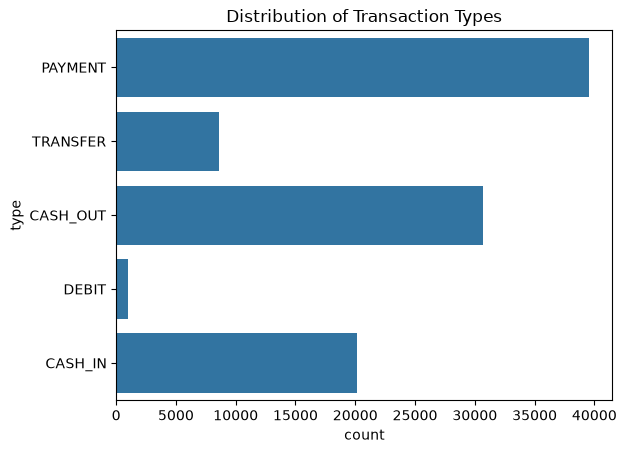

In [19]:
sns.countplot(data["type"])
plt.title("Distribution of Transaction Types")
plt.show()

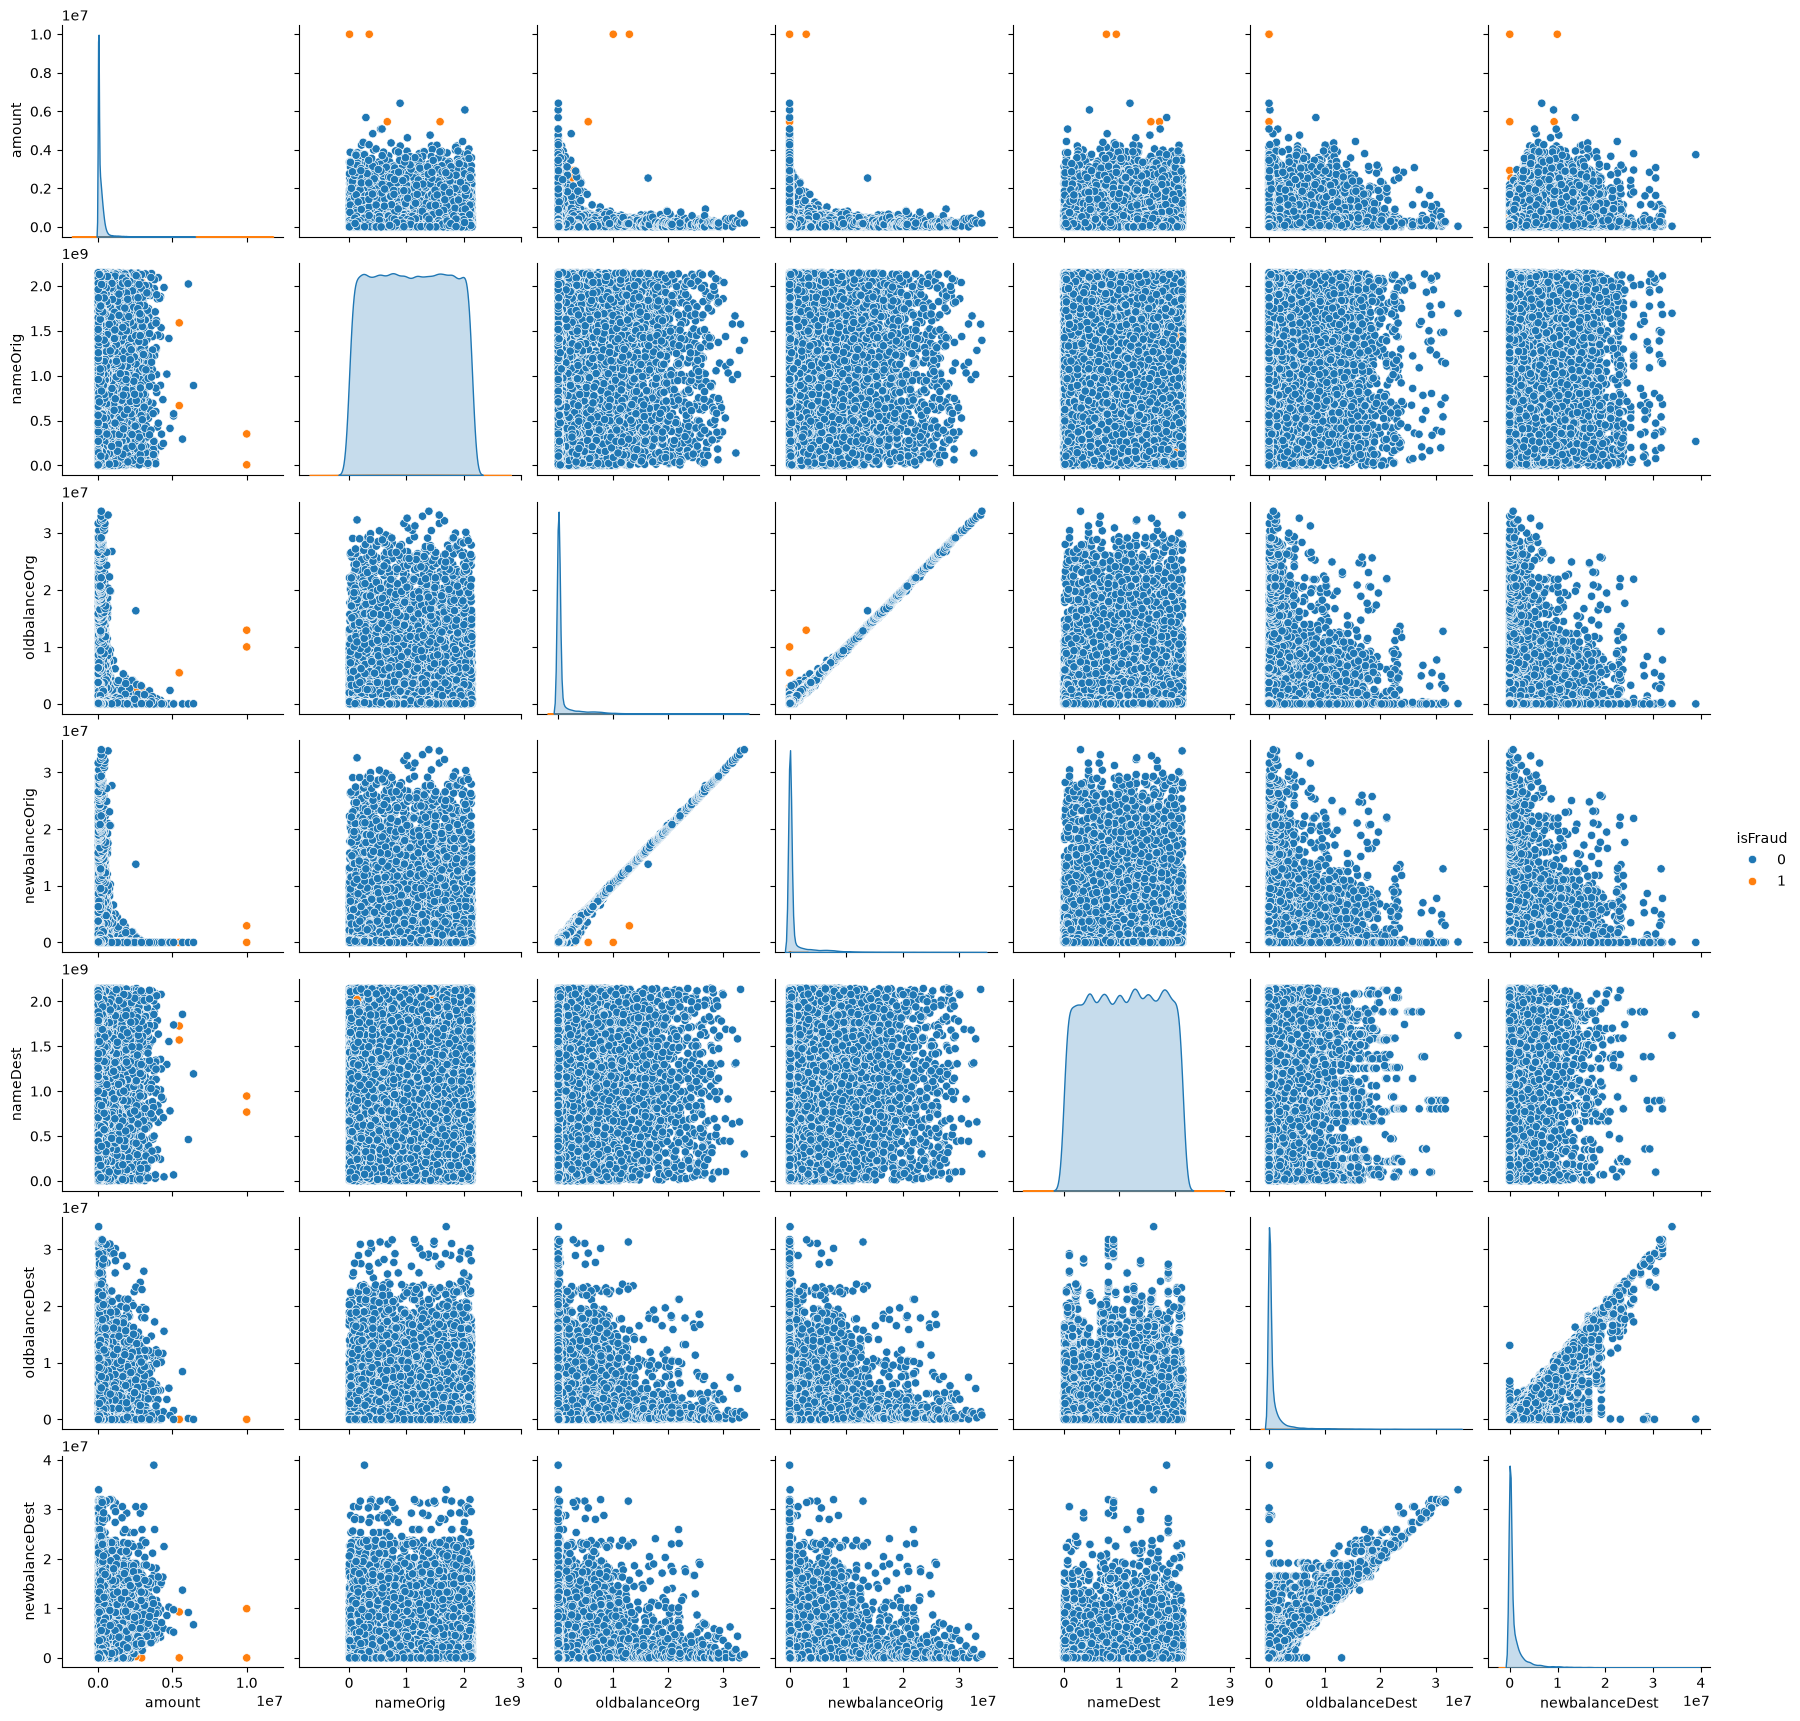

In [20]:
sns.pairplot(data,hue='isFraud')
plt.show()

# Outlier Detection and Encoding

In [21]:
le=LabelEncoder()
data['type']=le.fit_transform(data['type'])

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'type'),
  Text(1, 0, 'amount'),
  Text(2, 0, 'nameOrig'),
  Text(3, 0, 'oldbalanceOrg'),
  Text(4, 0, 'newbalanceOrig'),
  Text(5, 0, 'nameDest'),
  Text(6, 0, 'oldbalanceDest'),
  Text(7, 0, 'newbalanceDest'),
  Text(8, 0, 'isFraud')])

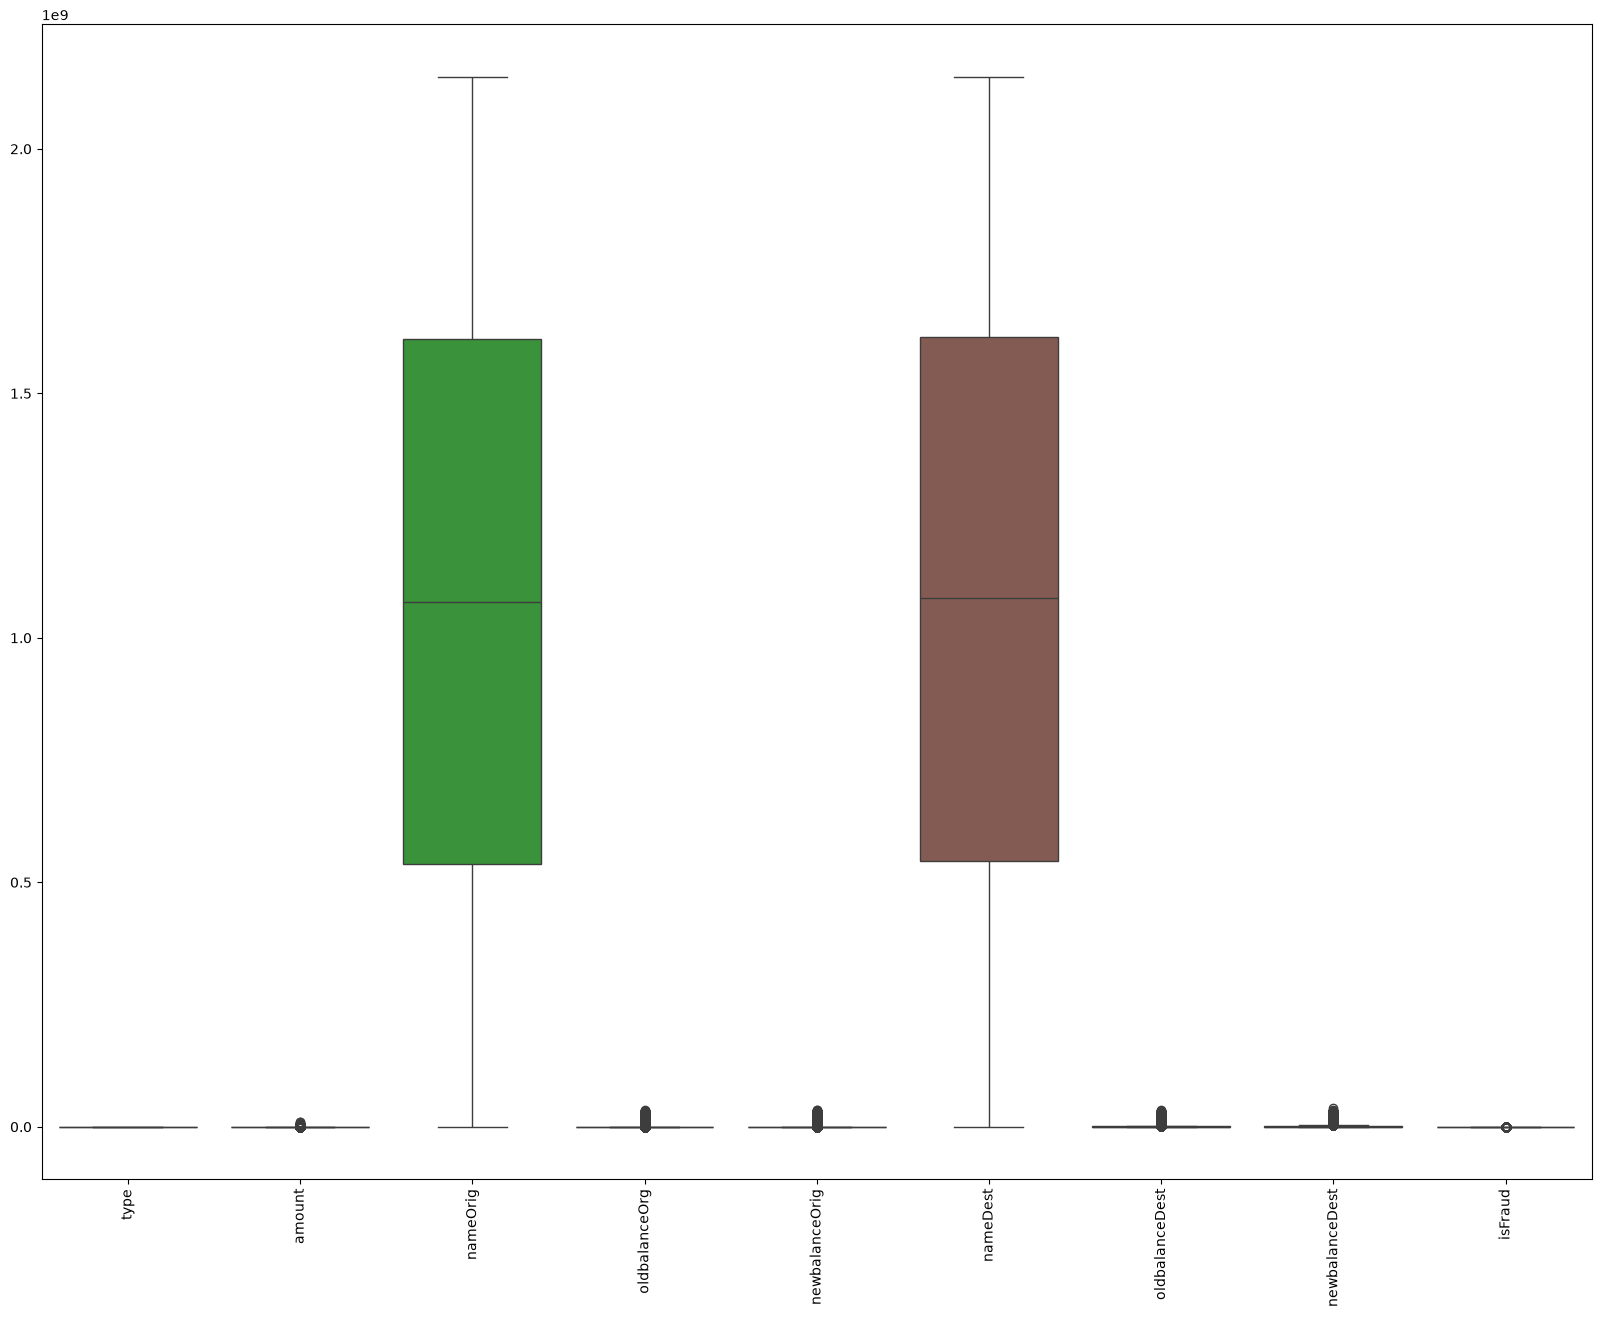

In [22]:
plt.figure(figsize=(20,15))
sns.boxplot(data)
plt.xticks(rotation=90)

In [23]:
# col=['type','amount','nameOrig','oldbalanceOrg','newbalanceOrig','nameDest','oldbalanceDest','newbalanceDest','isFraud','isFlaggedFraud']
# plt.figure(figsize=(15,10),layout="constrained")
# for i in range(len(col)):
#     plt.subplot(4,4,i+1)
#     sns.boxplot(data=data,x=col[i])
#     plt.title(col[i])
# plt.show()

# Outlier Treating

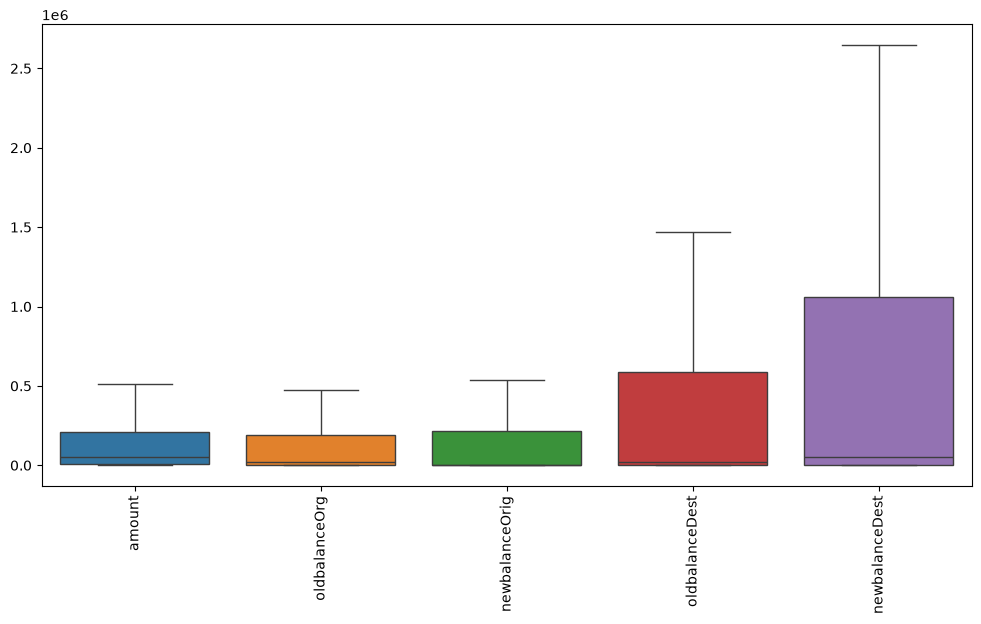

In [24]:
outlier = ['amount', 'oldbalanceOrg', 'newbalanceOrig','oldbalanceDest', 'newbalanceDest']
for i in outlier:
    Q1 = data[i].quantile(0.25)
    Q3 = data[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    data.loc[data[i] <= lower_limit, i] = lower_limit
    data.loc[data[i] >= upper_limit, i] = upper_limit
plt.figure(figsize=(12, 6))
sns.boxplot(data=data[outlier])
plt.xticks(rotation=90)
plt.show()

In [25]:
data.select_dtypes(include='number').corr()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
type,1.000000,-0.174845,-0.000650,-0.353934,-0.454604,-0.000179,-0.334161,-0.216779,0.015555
amount,-0.174845,1.000000,-0.000353,0.023674,0.016497,0.005843,0.484549,0.570081,0.007245
nameOrig,-0.000650,-0.000353,1.000000,0.001776,0.003717,-0.002106,0.000678,-0.002180,-0.002210
oldbalanceOrg,-0.353934,0.023674,0.001776,1.000000,0.927840,0.001834,0.149557,0.056127,0.003569
newbalanceOrig,-0.454604,0.016497,0.003717,0.927840,1.000000,0.002617,0.145086,0.022319,-0.020662
nameDest,-0.000179,0.005843,-0.002106,0.001834,0.002617,1.000000,0.011279,0.012752,-0.004905
oldbalanceDest,-0.334161,0.484549,0.000678,0.149557,0.145086,0.011279,1.000000,0.867379,-0.018138
newbalanceDest,-0.216779,0.570081,-0.002180,0.056127,0.022319,0.012752,0.867379,1.000000,-0.011079
isFraud,0.015555,0.007245,-0.002210,0.003569,-0.020662,-0.004905,-0.018138,-0.011079,1.000000


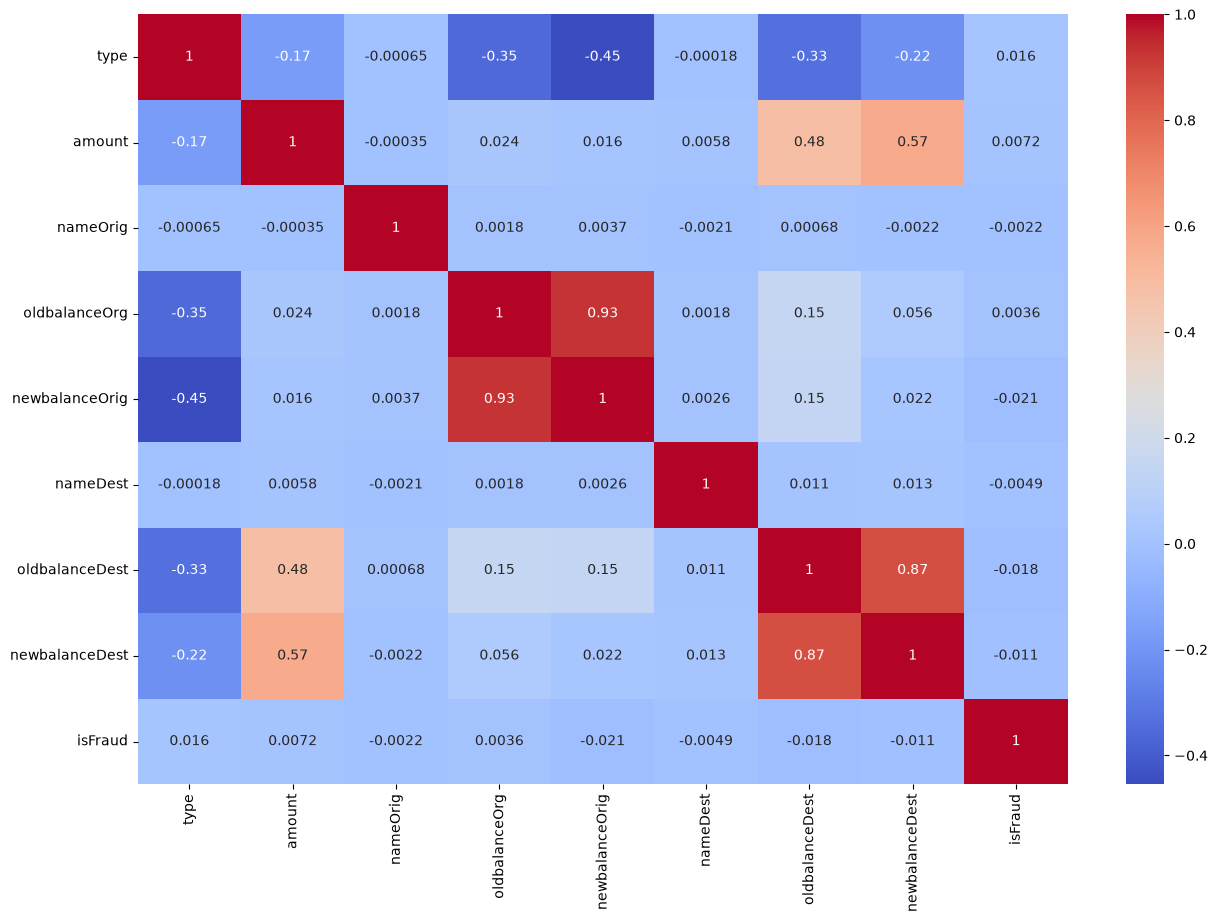

In [26]:
plt.figure(figsize=(15,10))
sns.heatmap(data.select_dtypes(include='number').corr(),annot=True,cmap="coolwarm")
plt.show()

# Splitting data

In [27]:
x=data.drop("isFraud",axis=1)
x

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest
0,3,9839.64,1231006815,170136.0,160296.36,1979787155,0.00,0.00
1,3,1864.28,1666544295,21249.0,19384.72,2044282225,0.00,0.00
2,4,181.00,1305486145,181.0,0.00,553264065,0.00,0.00
3,1,181.00,840083671,181.0,0.00,38997010,21182.00,0.00
4,3,11668.14,2048537720,41554.0,29885.86,1230701703,0.00,0.00
...,...,...,...,...,...,...,...,...
99995,3,4020.66,1410794718,159929.0,155908.34,1257036576,0.00,0.00
99996,3,18345.49,744303677,6206.0,0.00,1785344556,0.00,0.00
99997,0,183774.91,104331851,39173.0,222947.91,36392889,54925.05,0.00
99998,1,82237.17,707662966,6031.0,0.00,1553004158,592635.66,799140.46


In [28]:
y=data["isFraud"]
y

0        0
1        0
2        1
3        1
4        0
        ..
99995    0
99996    0
99997    0
99998    0
99999    0
Name: isFraud, Length: 100000, dtype: int64

In [29]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.3,random_state=42)

# Normalization

In [30]:
scaler=StandardScaler()
xtrain=scaler.fit_transform(xtrain)
xtest=scaler.transform(xtest)

In [31]:
xtrain

array([[ 0.84421814, -0.69754693, -0.6699483 , ...,  1.06860333,
        -0.68575402, -0.68494961],
       [-0.63401358, -0.59048159, -0.07519477, ..., -0.9294101 ,
         0.8206094 ,  0.88725529],
       [-1.37312944,  1.42758179,  0.02285375, ...,  1.03031977,
        -0.66997362, -0.68494961],
       ...,
       [-0.63401358,  1.64625457, -1.02694   , ...,  0.3077335 ,
         0.87152538,  0.49398499],
       [-0.63401358, -0.22282284, -1.71706438, ...,  1.08589895,
        -0.48000514, -0.39305096],
       [ 0.84421814, -0.78544923, -0.19094917, ...,  1.43879192,
        -0.68575402, -0.68494961]], shape=(70000, 8))

# Checking for Imbalance and Removing It

In [32]:
from imblearn.over_sampling import SMOTE

print("Before Smote: ",data["isFraud"].value_counts())
smote=SMOTE(random_state=42)
xtrain,ytrain=smote.fit_resample(xtrain,ytrain)
print("After SMOTE:")
print(ytrain.value_counts())

Before Smote:  isFraud
0    99884
1      116
Name: count, dtype: int64
After SMOTE:
isFraud
0    69917
1    69917
Name: count, dtype: int64


In [33]:
# INITIAL MODEL BUILDING

# LOGISTIC REGRESSION

In [34]:
lr=LogisticRegression()
lr.fit(xtrain,ytrain)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [35]:
ypred_train=lr.predict(xtrain)
ypred_test=lr.predict(xtest)
print("Train Accuracy: ",lr.score(xtrain,ytrain))
print("Test Accuracy: ",lr.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
lr_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",lr_acc)

Train Accuracy:  0.8542629117382039
Test Accuracy:  0.8067333333333333
[[24173  5794]
 [    4    29]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.81      0.89     29967
           1       0.00      0.88      0.01        33

    accuracy                           0.81     30000
   macro avg       0.50      0.84      0.45     30000
weighted avg       1.00      0.81      0.89     30000


Model Accuracy:  80.67333333333333


# DECISION TREE

In [36]:
dt=DecisionTreeClassifier(criterion='gini',max_depth=5,random_state=45)
dt.fit(xtrain,ytrain)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",45
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [37]:
ypred_train=dt.predict(xtrain)
ypred_test=dt.predict(xtest)
print("Train Accuracy: ",dt.score(xtrain,ytrain))
print("Test Accuracy: ",dt.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
dt_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",dt_acc)

Train Accuracy:  0.963106254558977
Test Accuracy:  0.9544
[[28603  1364]
 [    4    29]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.95      0.98     29967
           1       0.02      0.88      0.04        33

    accuracy                           0.95     30000
   macro avg       0.51      0.92      0.51     30000
weighted avg       1.00      0.95      0.98     30000


Model Accuracy:  95.44


# RANDOM FOREST

In [38]:
rf=RandomForestClassifier(n_estimators=100,criterion='gini',max_depth=5,random_state=42)
rf.fit(xtrain,ytrain)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [39]:
ypred_train=rf.predict(xtrain)
ypred_test=rf.predict(xtest)
print("Train Accuracy: ",rf.score(xtrain,ytrain))
print("Test Accuracy: ",rf.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
rf_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",rf_acc)

Train Accuracy:  0.9557618318863795
Test Accuracy:  0.9103666666666667
[[27282  2685]
 [    4    29]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.91      0.95     29967
           1       0.01      0.88      0.02        33

    accuracy                           0.91     30000
   macro avg       0.51      0.89      0.49     30000
weighted avg       1.00      0.91      0.95     30000


Model Accuracy:  91.03666666666666


# ADABOOST

In [40]:
ada=AdaBoostClassifier(n_estimators=100,learning_rate=0.5,random_state=42)
ada.fit(xtrain,ytrain)

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.28,0.32,0.38,...,0.41,0.46,0.41]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[0.48,0.37,0.25,...,0.17,0.09,0.19]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](8,)","[0.17,0.02,0. ,...,0. ,0.04,0.03]"


In [41]:
ypred_train=ada.predict(xtrain)
ypred_test=ada.predict(xtest)
print("Train Accuracy: ",ada.score(xtrain,ytrain))
print("Test Accuracy: ",ada.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
ada_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",ada_acc)

Train Accuracy:  0.9033425347197391
Test Accuracy:  0.8401
[[25173  4794]
 [    3    30]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.84      0.91     29967
           1       0.01      0.91      0.01        33

    accuracy                           0.84     30000
   macro avg       0.50      0.87      0.46     30000
weighted avg       1.00      0.84      0.91     30000


Model Accuracy:  84.00999999999999


# GRADIENT BOOST

In [42]:
gb=GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)
gb.fit(xtrain,ytrain)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [43]:
ypred_train=gb.predict(xtrain)
ypred_test=gb.predict(xtest)
print("Train Accuracy: ",gb.score(xtrain,ytrain))
print("Test Accuracy: ",gb.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
gb_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",gb_acc)

Train Accuracy:  0.9885149534447988
Test Accuracy:  0.9784666666666667
[[29324   643]
 [    3    30]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99     29967
           1       0.04      0.91      0.08        33

    accuracy                           0.98     30000
   macro avg       0.52      0.94      0.54     30000
weighted avg       1.00      0.98      0.99     30000


Model Accuracy:  97.84666666666666


# XG BOOST

In [44]:
xgb=XGBClassifier(n_estimators=100,max_depth=5,random_state=42)
xgb.fit(xtrain,ytrain)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [45]:
ypred_train=xgb.predict(xtrain)
ypred_test=xgb.predict(xtest)
print("Train Accuracy: ",xgb.score(xtrain,ytrain))
print("Test Accuracy: ",xgb.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
xgb_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",xgb_acc)

Train Accuracy:  0.9996066764878355
Test Accuracy:  0.9978333333333333
[[29907    60]
 [    5    28]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     29967
           1       0.32      0.85      0.46        33

    accuracy                           1.00     30000
   macro avg       0.66      0.92      0.73     30000
weighted avg       1.00      1.00      1.00     30000


Model Accuracy:  99.78333333333333


# KNN

In [46]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(xtrain,ytrain)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [47]:
ypred_train=knn.predict(xtrain)
ypred_test=knn.predict(xtest)
print("Train Accuracy: ",knn.score(xtrain,ytrain))
print("Test Accuracy: ",knn.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
knn_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",knn_acc)

Train Accuracy:  0.995015518400389
Test Accuracy:  0.9861666666666666
[[29568   399]
 [   16    17]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99     29967
           1       0.04      0.52      0.08        33

    accuracy                           0.99     30000
   macro avg       0.52      0.75      0.53     30000
weighted avg       1.00      0.99      0.99     30000


Model Accuracy:  98.61666666666666


# NAIVE BAYES

In [48]:
gnb=GaussianNB()
gnb.fit(xtrain,ytrain)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[69917.,69917.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.334e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[-0. ,-0. , 0. ,..., 0. , 0. , 0. ], [ 0.3 , 0.25,-0.13,...,-0.13,-0.52,-0.3 ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[1. ,1. ,1. ,...,1. ,1. ,1. ], [1.19,1.64,0.69,...,1.04,0.23,0.55]]"


In [49]:
ypred_train=gnb.predict(xtrain)
ypred_test=gnb.predict(xtest)
print("Train Accuracy: ",gnb.score(xtrain,ytrain))
print("Test Accuracy: ",gnb.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
gnb_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",gnb_acc)

Train Accuracy:  0.6951456727262325
Test Accuracy:  0.4654333333333333
[[13930 16037]
 [    0    33]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.46      0.63     29967
           1       0.00      1.00      0.00        33

    accuracy                           0.47     30000
   macro avg       0.50      0.73      0.32     30000
weighted avg       1.00      0.47      0.63     30000


Model Accuracy:  46.54333333333333


# SUPPORT VECTOR MACHINE(SVM)

In [50]:
# LINEAR
svc_linear=SVC(kernel="linear")
svc_linear.fit(xtrain,ytrain)

ypred_train=svc_linear.predict(xtrain)
ypred_test=svc_linear.predict(xtest)
print("Train Accuracy: ",svc_linear.score(xtrain,ytrain))
print("Test Accuracy: ",svc_linear.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
svc_linear_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",svc_linear_acc)

Train Accuracy:  0.8651472460202811
Test Accuracy:  0.8072333333333334
[[24188  5779]
 [    4    29]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.81      0.89     29967
           1       0.00      0.88      0.01        33

    accuracy                           0.81     30000
   macro avg       0.50      0.84      0.45     30000
weighted avg       1.00      0.81      0.89     30000


Model Accuracy:  80.72333333333333


In [51]:
# # POLY
# svc_poly=SVC(kernel="poly",degree=3,gamma=6,C=7)
# svc_poly.fit(xtrain,ytrain)

# ypred_train=svc_poly.predict(xtrain)
# ypred_test=svc_poly.predict(xtest)
# print("Train Accuracy: ",svc_poly.score(xtrain,ytrain))
# print("Test Accuracy: ",svc_poly.score(xtest,ytest))

# cm=confusion_matrix(ytest,ypred_test)
# print(cm)
# print("Classification Report:\n",classification_report(ytest,ypred_test))
# print()
# svc_poly_acc=accuracy_score(ytest,ypred_test)*100
# print("Model Accuracy: ",svc_poly_acc)

In [52]:
# # SIGMOID
# svc_sig=SVC(kernel="sigmoid",gamma=2,C=5)
# svc_sig.fit(xtrain,ytrain)

# ypred_train=svc_sig.predict(xtrain)
# ypred_test=svc_sig.predict(xtest)
# print("Train Accuracy: ",svc_sig.score(xtrain,ytrain))
# print("Test Accuracy: ",svc_sig.score(xtest,ytest))

# cm=confusion_matrix(ytest,ypred_test)
# print(cm)
# print("Classification Report:\n",classification_report(ytest,ypred_test))
# print()
# svc_sig_acc=accuracy_score(ytest,ypred_test)*100
# print("Model Accuracy: ",svc_sig_acc)

In [53]:
svc_rbf=SVC()
svc_rbf.fit(xtrain,ytrain)

ypred_train=svc_rbf.predict(xtrain)
ypred_test=svc_rbf.predict(xtest)
print("Train Accuracy: ",svc_rbf.score(xtrain,ytrain))
print("Test Accuracy: ",svc_rbf.score(xtest,ytest))

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
svc_rbf_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",svc_rbf_acc)

Train Accuracy:  0.9881716892887281
Test Accuracy:  0.9761333333333333
[[29254   713]
 [    3    30]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99     29967
           1       0.04      0.91      0.08        33

    accuracy                           0.98     30000
   macro avg       0.52      0.94      0.53     30000
weighted avg       1.00      0.98      0.99     30000


Model Accuracy:  97.61333333333333


In [54]:
tb = pd.DataFrame()
tb['Model'] = pd.Series(['K-Nearest Neighbors', 'Logistic Regression', 'Naive Bayes', 'Random Forest', 'AdaBoost', 'Gradient Boosting Classifier', 'Decision Tree', 'SVC Linear', 'SVC RBF', 'XGBoost'])
tb['Accuracy'] = pd.Series([knn_acc, lr_acc, gnb_acc, rf_acc, ada_acc, gb_acc, dt_acc, svc_linear_acc, svc_rbf_acc, xgb_acc])
tb

,Model,Accuracy
0,K-Nearest Neighbors,98.616667
1,Logistic Regression,80.673333
2,Naive Bayes,46.543333
3,Random Forest,91.036667
4,AdaBoost,84.010000
5,Gradient Boosting Classifier,97.846667
6,Decision Tree,95.440000
7,SVC Linear,80.723333
8,SVC RBF,97.613333
9,XGBoost,99.783333


# HYPER PARAMETER TUNING THE MODELS

##### 1. KNN

In [55]:
par={'n_neighbors':[3,5,27,59,11],'weights':['uniform','distance'],'algorithm':['auto','ball_tree','kd_tree']}
knt=GridSearchCV(knn,par,cv=10,scoring='accuracy')
knt.fit(xtrain,ytrain)
print(knt.best_params_)
print(knt.best_score_) 

{'algorithm': 'auto', 'n_neighbors': 3, 'weights': 'distance'}
0.9947938283918148


In [56]:
knnt=KNeighborsClassifier(n_neighbors=3,weights="distance",algorithm="auto")
knnt.fit(xtrain,ytrain)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [57]:
ypred_train=knnt.predict(xtrain)
ypred_test=knnt.predict(xtest)
knnt_train_acc=knnt.score(xtrain,ytrain)*100
knnt_test_acc=knnt.score(xtest,ytest)*100
print("Train Accuracy: ",knnt_train_acc)
print("Test Accuracy: ",knnt_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
knnt_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",knnt_acc)

Train Accuracy:  100.0
Test Accuracy:  98.92999999999999
[[29663   304]
 [   17    16]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99     29967
           1       0.05      0.48      0.09        33

    accuracy                           0.99     30000
   macro avg       0.52      0.74      0.54     30000
weighted avg       1.00      0.99      0.99     30000


Model Accuracy:  98.92999999999999


##### 2. LR

In [58]:
par={'C':[0.1,1,10],'penalty':['l1','l2'],'solver':['liblinear','saga']}
lrt=GridSearchCV(lr,par,cv=10,scoring='accuracy')
lrt.fit(xtrain, ytrain)
print(lrt.best_params_)
print(lrt.best_score_)

{'C': 1, 'penalty': 'l1', 'solver': 'saga'}
0.8542343091791258


In [59]:
lr_t=LogisticRegression(C=10,penalty='l2',solver='saga')
lr_t.fit(xtrain,ytrain)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may no

In [60]:
ypred_train=lr_t.predict(xtrain)
ypred_test=lr_t.predict(xtest)
lr_train_acc=lr_t.score(xtrain,ytrain)*100
lr_test_acc=lr_t.score(xtest,ytest)*100
print("Train Accuracy: ",lr_train_acc)
print("Test Accuracy: ",lr_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
lr_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",lr_t_acc)

Train Accuracy:  85.44488464894089
Test Accuracy:  80.70333333333333
[[24182  5785]
 [    4    29]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.81      0.89     29967
           1       0.00      0.88      0.01        33

    accuracy                           0.81     30000
   macro avg       0.50      0.84      0.45     30000
weighted avg       1.00      0.81      0.89     30000


Model Accuracy:  80.70333333333333


##### 3. NB

In [61]:
par = {'var_smoothing':[1e-9, 1e-8, 1e-7, 1e-6]}
nbt = GridSearchCV(gnb,par, cv=10, scoring='accuracy')
nbt.fit(xtrain,ytrain)
print(nbt.best_params_)
print(nbt.best_score_)

{'var_smoothing': 1e-09}
0.6952029038080074


In [62]:
gnb_t=GaussianNB(var_smoothing=1e-09)
gnb_t.fit(xtrain,ytrain)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[69917.,69917.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.334e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[-0. ,-0. , 0. ,..., 0. , 0. , 0. ], [ 0.3 , 0.25,-0.13,...,-0.13,-0.52,-0.3 ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[1. ,1. ,1. ,...,1. ,1. ,1. ], [1.19,1.64,0.69,...,1.04,0.23,0.55]]"


In [63]:
ypred_train=gnb_t.predict(xtrain)
ypred_test=gnb_t.predict(xtest)
gnb_train_acc=gnb_t.score(xtrain,ytrain)*100
gnb_test_acc=gnb_t.score(xtest,ytest)*100
print("Train Accuracy: ",gnb_train_acc)
print("Test Accuracy: ",gnb_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
gnb_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",gnb_t_acc)

Train Accuracy:  69.51456727262325
Test Accuracy:  46.54333333333333
[[13930 16037]
 [    0    33]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.46      0.63     29967
           1       0.00      1.00      0.00        33

    accuracy                           0.47     30000
   macro avg       0.50      0.73      0.32     30000
weighted avg       1.00      0.47      0.63     30000


Model Accuracy:  46.54333333333333


##### 4. RF

In [64]:
par={'n_estimators':[100,200],'max_depth':[5,10,15],'max_features':['sqrt','log2']}
rft=GridSearchCV(rf, par, cv=5, scoring='accuracy')
rft.fit(xtrain,ytrain)
print(rft.best_params_)
print(rft.best_score_)

{'max_depth': 15, 'max_features': 'log2', 'n_estimators': 100}
0.9985911875619307


In [65]:
rf_t=RandomForestClassifier(n_estimators=100,max_depth=15,max_features='log2',random_state=42)
rf_t.fit(xtrain,ytrain)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [66]:
ypred_train=rf_t.predict(xtrain)
ypred_test=rf_t.predict(xtest)
rf_train_acc=rf_t.score(xtrain,ytrain)*100
rf_test_acc=rf_t.score(xtest,ytest)*100
print("Train Accuracy: ",rf_train_acc)
print("Test Accuracy: ",rf_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
rf_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",rf_t_acc)

Train Accuracy:  99.92133529756711
Test Accuracy:  99.70666666666666
[[29892    75]
 [   13    20]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     29967
           1       0.21      0.61      0.31        33

    accuracy                           1.00     30000
   macro avg       0.61      0.80      0.66     30000
weighted avg       1.00      1.00      1.00     30000


Model Accuracy:  99.70666666666666


##### 5. ADB

In [67]:
par={'n_estimators':[50,100,150], 'learning_rate':[0.1,0.5,1.0]}
adt=GridSearchCV(ada, par, cv=5, scoring='accuracy')
adt.fit(xtrain, ytrain)
print(adt.best_params_)
print(adt.best_score_)

{'learning_rate': 1.0, 'n_estimators': 150}
0.966832109249139


In [68]:
ada_t=AdaBoostClassifier(n_estimators=150,learning_rate=1.0,random_state=42)
ada_t.fit(xtrain,ytrain)

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",150
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](150,)","[0.28,0.32,0.23,...,0.49,0.49,0.49]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](150,)","[0.97,0.76,1.19,...,0.05,0.05,0.04]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](8,)","[0.3 ,0.07,0.01,...,0.02,0.04,0.03]"


In [69]:
ypred_train=ada_t.predict(xtrain)
ypred_test=ada_t.predict(xtest)
ada_train_acc=ada_t.score(xtrain,ytrain)*100
ada_test_acc=ada_t.score(xtest,ytest)*100
print("Train Accuracy: ",ada_train_acc)
print("Test Accuracy: ",ada_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
ada_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",ada_t_acc)

Train Accuracy:  96.98928729779595
Test Accuracy:  94.67999999999999
[[28373  1594]
 [    2    31]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.95      0.97     29967
           1       0.02      0.94      0.04        33

    accuracy                           0.95     30000
   macro avg       0.51      0.94      0.51     30000
weighted avg       1.00      0.95      0.97     30000


Model Accuracy:  94.67999999999999


##### 6. GBC

In [70]:
par={'n_estimators':[50,100,150],'max_depth':[2,3,5]}
gbt=GridSearchCV(gb,par,cv=5,scoring='accuracy')
gbt.fit(xtrain, ytrain)
print(gbt.best_params_)
print(gbt.best_score_)

{'max_depth': 5, 'n_estimators': 150}
0.9972324338662529


In [71]:
gb_t=GradientBoostingClassifier(n_estimators=150,learning_rate=0.1,max_depth=5,random_state=42)
gb_t.fit(xtrain,ytrain)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",150
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [72]:
ypred_train=gb_t.predict(xtrain)
ypred_test=gb_t.predict(xtest)
gb_train_acc=gb_t.score(xtrain,ytrain)*100
gb_test_acc=gb_t.score(xtest,ytest)*100
print("Train Accuracy: ",gb_train_acc)
print("Test Accuracy: ",gb_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
gb_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",gb_t_acc)

Train Accuracy:  99.85625813464537
Test Accuracy:  99.52666666666666
[[29830   137]
 [    5    28]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     29967
           1       0.17      0.85      0.28        33

    accuracy                           1.00     30000
   macro avg       0.58      0.92      0.64     30000
weighted avg       1.00      1.00      1.00     30000


Model Accuracy:  99.52666666666666


##### 7. XGB

In [73]:
par = {'max_depth':[3,5,7], 'n_estimators':[50,100,150]}
xgt = GridSearchCV(xgb, par, cv=5, scoring='accuracy')
xgt.fit(xtrain,ytrain)
print(xgt.best_params_)
print(xgt.best_score_)

{'max_depth': 7, 'n_estimators': 150}
0.9989845097956079


In [74]:
xgb_t=XGBClassifier(n_estimators=150,max_depth=7,random_state=42)
xgb_t.fit(xtrain,ytrain)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [75]:
ypred_train=xgb_t.predict(xtrain)
ypred_test=xgb_t.predict(xtest)
xgb_train_acc=xgb_t.score(xtrain,ytrain)*100
xgb_test_acc=xgb_t.score(xtest,ytest)*100
print("Train Accuracy: ",xgb_train_acc)
print("Test Accuracy: ",xgb_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
xgb_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",xgb_t_acc)

Train Accuracy:  100.0
Test Accuracy:  99.81333333333333
[[29917    50]
 [    6    27]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     29967
           1       0.35      0.82      0.49        33

    accuracy                           1.00     30000
   macro avg       0.68      0.91      0.74     30000
weighted avg       1.00      1.00      1.00     30000


Model Accuracy:  99.81333333333333


##### 8. DT

In [76]:
par={'max_depth':[3,5,7],'criterion':['gini','entropy']}
dtt=GridSearchCV(dt, par, cv=5, scoring='accuracy')
dtt.fit(xtrain, ytrain)
print(dtt.best_params_)
print(dtt.best_score_)

{'criterion': 'gini', 'max_depth': 7}
0.9763362409934201


In [77]:
dt_t=DecisionTreeClassifier(criterion='gini',max_depth=7,random_state=42)
dt_t.fit(xtrain,ytrain)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [78]:
ypred_train=dt_t.predict(xtrain)
ypred_test=dt_t.predict(xtest)
dt_train_acc=dt_t.score(xtrain,ytrain)*100
dt_test_acc=dt_t.score(xtest,ytest)*100
print("Train Accuracy: ",dt_train_acc)
print("Test Accuracy: ",dt_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
dt_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",dt_t_acc)

Train Accuracy:  97.67295507530356
Test Accuracy:  97.41
[[29198   769]
 [    8    25]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.97      0.99     29967
           1       0.03      0.76      0.06        33

    accuracy                           0.97     30000
   macro avg       0.52      0.87      0.52     30000
weighted avg       1.00      0.97      0.99     30000


Model Accuracy:  97.41


##### 9. SVC

In [79]:
par={'C':[1,5,10], 'kernel':['rbf'], 'gamma':['scale','auto']}
svct=GridSearchCV(svc_rbf, par, cv=5, scoring='accuracy')
svct.fit(xtrain,ytrain)
print(svct.best_params_)
print(svct.best_score_)

{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
0.9938856084973064


In [80]:
svc_t=SVC(C=20,gamma="auto",kernel="rbf")
svc_t.fit(xtrain,ytrain)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",20
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [81]:
ypred_train=svc_t.predict(xtrain)
ypred_test=svc_t.predict(xtest)
svc_train_acc=svc_t.score(xtrain,ytrain)*100
svc_test_acc=svc_t.score(xtest,ytest)*100
print("Train Accuracy: ",svc_train_acc)
print("Test Accuracy: ",svc_test_acc)

cm=confusion_matrix(ytest,ypred_test)
print(cm)
print("Classification Report:\n",classification_report(ytest,ypred_test))
print()
svc_t_acc=accuracy_score(ytest,ypred_test)*100
print("Model Accuracy: ",svc_t_acc)

Train Accuracy:  99.56376846832673
Test Accuracy:  99.06
[[29696   271]
 [   11    22]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00     29967
           1       0.08      0.67      0.13        33

    accuracy                           0.99     30000
   macro avg       0.54      0.83      0.57     30000
weighted avg       1.00      0.99      0.99     30000


Model Accuracy:  99.06


# TEST AND TRAIN ACCURACY

In [82]:
tb1=pd.DataFrame()
tb1['Model'] = pd.Series(['KNN', 'Logistic Regression', 'Naive Bayes', 'Random Forest', 'AdaBoost', 'Gradient Boosting', 'XGBoost', 'Decision Tree', 'SVC'])
tb1['Train Accuracy'] = pd.Series([knnt_train_acc, lr_train_acc, gnb_train_acc, rf_train_acc, ada_train_acc, gb_train_acc, xgb_train_acc, dt_train_acc, svc_train_acc])
tb1['Test Accuracy'] = pd.Series([knnt_acc, lr_t_acc, gnb_t_acc, rf_t_acc, ada_t_acc, gb_t_acc, xgb_t_acc, dt_t_acc, svc_t_acc])
tb1

,Model,Train Accuracy,Test Accuracy
0,KNN,100.000000,98.930000
1,Logistic Regression,85.444885,80.703333
2,Naive Bayes,69.514567,46.543333
3,Random Forest,99.921335,99.706667
4,AdaBoost,96.989287,94.680000
5,Gradient Boosting,99.856258,99.526667
6,XGBoost,100.000000,99.813333
7,Decision Tree,97.672955,97.410000
8,SVC,99.563768,99.060000


In [85]:
import joblib
joblib.dump(xgb_t,'Payments_fraud_detection_model.pkl')

['Payments_fraud_detection_model.pkl']

In [86]:
joblib.dump(scaler,'scaler.pkl')

['scaler.pkl']